# Latencia de la aplicación desplegada

Este notebook cronometra **las mismas funciones que invoca la aplicación**

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "corpus.json").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

print("Raíz del proyecto:", ROOT)

Raíz del proyecto: /Users/cristiansandoval/Universidad/Semillero/ButterflyModeling


In [2]:
import io
import time

import numpy as np
import pandas as pd
from PIL import Image

from scripts import corpus, gradcam, recorte
from scripts import modelRegistry as registro
from scripts.architectures import preprocessFn
from scripts.vizStyle import SERIE_1, SERIE_2, applyStyle

IMAGENES = 40          # fotos distintas, para que el tamaño de entrada varíe como en uso real
CALENTAMIENTO = 3
FIGURAS = registro.OUTPUTS_DIR / "figuras"
FIGURAS.mkdir(exist_ok=True)

sitio = registro.readJson(registro.OUTPUTS_DIR / "desplegado.json")
RUN_ID = sitio["run_id"]
print(f"modelo del sitio: {sitio['architecture']} · {RUN_ID}")

modelo del sitio: mobilenet_v3_small · 20261021T203700Z_kd-respuesta-t2-a30-mobilenet-v3-small


## 1 · Arranque en frío

In [3]:
inicio = time.perf_counter()
detector = recorte.cargarDetector()
tDetector = time.perf_counter() - inicio

inicio = time.perf_counter()
modelo = registro.modeloInferencia(RUN_ID)
tModelo = time.perf_counter() - inicio

arquitectura = registro.loadRunConfig(RUN_ID)["architecture"]
preprocesar = preprocessFn(arquitectura)
clases = registro.loadRunMetrics(RUN_ID)["class_names"]

print(f"detector  {tDetector:6.2f} s")
print(f"modelo    {tModelo:6.2f} s")
print(f"total     {tDetector + tModelo:6.2f} s")

/opt/miniconda3/envs/semillero/lib/python3.12/site-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


detector    1.47 s
modelo      0.67 s
total       2.13 s


## 2 · Las fotos

In [4]:
reparto = corpus.manifiesto()["reparto"]
raizFotos = corpus.repoDataset() / "Insectos"

semilla = np.random.default_rng(42)
candidatas = [(especie, archivo) for especie, d in sorted(reparto.items())
              for archivo in d["test"]]
elegidas = [candidatas[i] for i in semilla.choice(len(candidatas), IMAGENES, replace=False)]

fotos = []
for especie, archivo in elegidas:
    ruta = raizFotos / especie / archivo
    if ruta.exists():
        fotos.append(ruta.read_bytes())
print(f"{len(fotos)} fotos · mediana {np.median([len(f) for f in fotos]) / 1e3:.0f} kB")

40 fotos · mediana 271 kB


## 3 · Cada etapa

In [5]:
def cronometrar(datos):
    """Una pasada completa, devolviendo los milisegundos de cada etapa."""
    t = {}
    inicio = time.perf_counter()
    imagen = Image.open(io.BytesIO(datos))
    imagen.load()
    t["decode"] = (time.perf_counter() - inicio) * 1000

    inicio = time.perf_counter()
    cuadrada, _ = recorte.preparar(detector, imagen)
    t["detect and crop"] = (time.perf_counter() - inicio) * 1000

    inicio = time.perf_counter()
    lote = preprocesar(np.asarray(cuadrada, dtype="float32")[None])
    probabilidades = modelo.predict(lote, verbose=0)[0]
    t["classify"] = (time.perf_counter() - inicio) * 1000

    inicio = time.perf_counter()
    mapa = gradcam.computeGradcam(modelo, cuadrada, int(np.argmax(probabilidades)), preprocesar)
    t["Grad-CAM"] = (time.perf_counter() - inicio) * 1000

    inicio = time.perf_counter()
    gradcam.overlayHeatmap(cuadrada, mapa)
    t["overlay"] = (time.perf_counter() - inicio) * 1000
    return t


for datos in fotos[:CALENTAMIENTO]:
    cronometrar(datos)

medidas = pd.DataFrame(cronometrar(datos) for datos in fotos)
medidas["TOTAL"] = medidas.sum(axis=1)

latencia = pd.DataFrame({
    "mediana_ms": medidas.median().round(1),
    "sd_ms": medidas.std().round(1),
    "p90_ms": medidas.quantile(0.90).round(1),
    "% del total": (medidas.median() / medidas.median()["TOTAL"] * 100).round(1),
})
latencia

,mediana_ms,sd_ms,p90_ms,% del total
decode,3.6,12.6,7.6,0.9
detect and crop,143.9,35.5,183.4,37.5
classify,50.7,12.3,58.6,13.2
Grad-CAM,175.8,42.2,222.8,45.8
overlay,1.3,1.4,2.3,0.3
TOTAL,384.2,68.6,513.7,100.0


## 4 · De dónde sale el tiempo

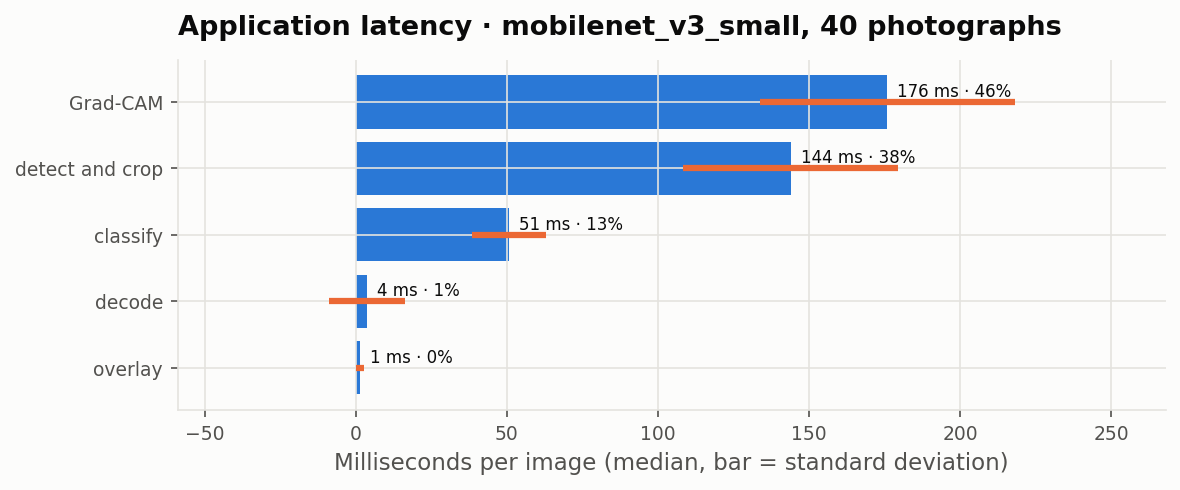

In [6]:
applyStyle()
import matplotlib.pyplot as plt

etapas = latencia.drop(index="TOTAL").sort_values("mediana_ms")
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(etapas.index, etapas["mediana_ms"], xerr=etapas["sd_ms"], color=SERIE_1, error_kw={"ecolor": SERIE_2, "elinewidth": 3})
for nombre, fila in etapas.iterrows():
    ax.annotate(f"{fila['mediana_ms']:.0f} ms · {fila['% del total']:.0f}%", (fila["mediana_ms"], nombre), xytext=(5, 5), textcoords="offset points", va="center", fontsize=8)
ax.margins(x=0.22)
ax.set(xlabel="Milliseconds per image (median, bar = standard deviation)", title=f"Application latency · {sitio['architecture']}, {len(fotos)} photographs")
fig.tight_layout()
fig.savefig(FIGURAS / "latencia_app.png", dpi=300, bbox_inches="tight")
plt.show()

## Registro

In [7]:
total = latencia.loc["TOTAL"]
soloModelo = latencia.loc["classify", "mediana_ms"]
print(f"Extremo a extremo: {total['mediana_ms']:.0f} ms (sd {total['sd_ms']:.0f}, p90 {total['p90_ms']:.0f}) sobre {len(fotos)} fotos de prueba.")
print(f"El clasificador son {soloModelo:.0f} ms, el {soloModelo / total['mediana_ms']:.0%} del total")
print(f"Arranque en frío: {tDetector + tModelo:.1f}s.")

registro.writeJson(registro.OUTPUTS_DIR / "latencia_app.json", {
    "run_id": RUN_ID,
    "arquitectura": sitio["architecture"],
    "imagenes": len(fotos),
    "etapas_ms": {k: {"mediana": float(v["mediana_ms"]), "sd": float(v["sd_ms"]),
                      "p90": float(v["p90_ms"])}
                  for k, v in latencia.iterrows()},
    "arranque_frio_s": {"detector": round(tDetector, 2), "modelo": round(tModelo, 2)},
})

Extremo a extremo: 384 ms (sd 69, p90 514) sobre 40 fotos de prueba.
El clasificador son 51 ms, el 13% del total
Arranque en frío: 2.1s.
